# Análise Exploratória e Limpeza de Dados de E-commerce
**Projeto de Análise de Dados (Online Retail)**  
*Autor: Vitor Emanuel*

---

### Sumário
1. [Introdução e Configuração do Ambiente](#1-introdução-e-configuração-do-ambiente)
2. [Diagnóstico da Base Bruta](#2-diagnóstico-da-base-bruta)
3. [Investigações Profundas (EDA)](#3-investigações-profundas-eda)
   - 3.1 Cancelamentos e Estornos
   - 3.2 Anomalias e Baixas de Estoque
   - 3.3 Inconsistências de Cadastro em Produtos
4. [Pipeline de Limpeza e Preparação dos Dados](#4-pipeline-de-limpeza-e-preparação-dos-dados)
5. [Análise de Desempenho e Visualizações de Negócio](#5-análise-de-desempenho-e-visualizações-de-negócio)
   - 5.1 Faturamento Mensal ao Longo do Tempo
   - 5.2 Top 10 Produtos Mais Vendidos
   - 5.3 Top 10 Países por Faturamento
6. [Conclusões e Principais Insights](#6-conclusões-e-principais-insights)


## 1. Introdução e Configuração do Ambiente

Este projeto tem como objetivo realizar uma **Análise Exploratória de Dados (EDA)** completa e a **limpeza rigorosa** da base de transações de um e-commerce multinacional com sede no Reino Unido. 

A base cobre o período de dezembro de 2010 a dezembro de 2011, contendo detalhes de transações de vendas em atacado e varejo.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais e de exibição
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)


## 2. Diagnóstico da Base Bruta

Carregamos o dataset bruto para identificar volume, tipos de dados e índice inicial de qualidade (duplicatas e valores ausentes).


In [2]:
# Carregamento do dataset original
df_vendas = pd.read_excel("../data/online-retail.xlsx")

print(f"Dimensões originais: {df_vendas.shape[0]:,} linhas e {df_vendas.shape[1]} colunas")
df_vendas.head()


Dimensões originais: 541,909 linhas e 8 colunas


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Tabela de diagnóstico de valores ausentes
tabela_diagnostico = pd.DataFrame({
    'Tipo': df_vendas.dtypes,
    'Valores Ausentes': df_vendas.isna().sum(),
    'Percentual (%)': (df_vendas.isna().mean() * 100).round(2)
}).sort_values(by='Valores Ausentes', ascending=False)

tabela_diagnostico


,Tipo,Valores Ausentes,Percentual (%)
CustomerID,float64,135080,24.93
Description,object,1454,0.27
StockCode,object,0,0.00
InvoiceNo,object,0,0.00
Quantity,int64,0,0.00
InvoiceDate,datetime64[us],0,0.00
UnitPrice,float64,0,0.00
Country,str,0,0.00


**Diagnóstico Inicial:**
* A base possui **541.909 registros**.
* `CustomerID` possui **135.080 valores ausentes** (~24,93%), correspondentes a compras como visitante (*guest checkout*).
* `Description` possui **1.454 registros nulos** (~0,27%).
* Identificadas **5.268 duplicatas 100% idênticas**.


## 3. Investigações Profundas (EDA)

Antes de realizar exclusões automáticas, investigamos a fundo cada anomalia presente no conjunto de dados.

### 3.1 Cancelamentos e Devoluções (Faturas com 'C')


In [4]:
# Identificando faturas de cancelamento (prefixo 'C')
filtro_cancelados = df_vendas['InvoiceNo'].astype(str).str.startswith('C')
df_cancelados = df_vendas[filtro_cancelados]

impacto_cancelados = (df_cancelados['Quantity'] * df_cancelados['UnitPrice']).sum()

print(f"Total de registros de cancelamento: {len(df_cancelados):,}")
print(f"Total de faturas únicas canceladas: {df_cancelados['InvoiceNo'].nunique():,}")
print(f"Impacto financeiro total dos estornos: £{impacto_cancelados:,.2f}")


Total de registros de cancelamento: 9,288
Total de faturas únicas canceladas: 3,836
Impacto financeiro total dos estornos: £-896,812.49


### 3.2 Anomalias de Inventário (Registros negativos sem 'C')

Identificamos 1.336 registros com quantidade negativa que **não possuíam o prefixo 'C'**. Investigamos esses casos:


In [5]:
filtro_anomalias = (df_vendas['Quantity'] < 0) & (~filtro_cancelados)
df_anomalias = df_vendas[filtro_anomalias]

print(f"Total de anomalias encontradas: {len(df_anomalias):,}")
print(f"Preço unitário médio: £{df_anomalias['UnitPrice'].mean():.2f} (100% com preço zero)")
print(f"Origem dos registros: {df_anomalias['Country'].unique()[0]} (100% Reino Unido)")
print(f"Clientes associados: {df_anomalias['CustomerID'].notna().sum()} (100% nulo)")

print("\nPrincipais anotações encontradas na descrição:")
df_anomalias['Description'].value_counts().head(8)


Total de anomalias encontradas: 1,336
Preço unitário médio: £0.00 (100% com preço zero)
Origem dos registros: United Kingdom (100% Reino Unido)
Clientes associados: 0 (100% nulo)

Principais anotações encontradas na descrição:


Description
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
Name: count, dtype: int64

**Conclusão sobre as anomalias:**
Esses 1.336 registros não representam compras de clientes. Tratam-se de **baixas operacionais de estoque** (produtos quebrados, testes de sistema, ajustes de inventário físico), que devem ser removidas da base comercial.


### 3.3 Inconsistências de Cadastro em Produtos

Investigamos códigos de estoque (`StockCode`) que possuíam mais de uma descrição associada.


In [6]:
# Códigos com múltiplas descrições
descricoes_por_codigo = df_vendas.groupby('StockCode')['Description'].nunique()
codigos_multiplos = descricoes_por_codigo[descricoes_por_codigo > 1]

# Verificando quantas dessas variações são resolvidas ao filtrar apenas preços comerciais (> 0)
df_650 = df_vendas[df_vendas['StockCode'].isin(codigos_multiplos.index)]
desc_comerciais = df_650[df_650['UnitPrice'] > 0].groupby('StockCode')['Description'].nunique()

print(f"Total de códigos com mais de 1 descrição: {len(codigos_multiplos)}")
print(f"Códigos resolvidos filtrando UnitPrice > 0: {(desc_comerciais == 1).sum()} (descrição comercial única)")
print(f"Códigos com variações legítimas de digitação: {(desc_comerciais > 1).sum()}")


Total de códigos com mais de 1 descrição: 650
Códigos resolvidos filtrando UnitPrice > 0: 429 (descrição comercial única)
Códigos com variações legítimas de digitação: 220


## 4. Pipeline de Limpeza e Preparação dos Dados

Com base nas evidências comprovadas na EDA, aplicamos o pipeline de higienização dos dados:
1. Remoção de duplicatas idênticas.
2. Remoção de registros sem descrição (ajustes operacionais com preço zero).
3. Separação das faturas de cancelamento.
4. Filtro de consistência de transações comerciais (`Quantity > 0` e `UnitPrice > 0`).
5. Criação do campo calculado `TotalVenda = Quantity * UnitPrice`.


In [7]:
# 1. Cópia limpa a partir do original
df_limpo = df_vendas.copy()
print(f"Base bruta inicial: {len(df_limpo):,} linhas")

# 2. Remoção de duplicatas exatas
duplicatas = df_limpo.duplicated().sum()
df_limpo = df_limpo.drop_duplicates()
print(f"Duplicatas exatas removidas: {duplicatas:,}")

# 3. Remoção de descrições ausentes
sem_desc = df_limpo['Description'].isna().sum()
df_limpo = df_limpo.dropna(subset=['Description'])
print(f"Registros sem descrição removidos: {sem_desc:,}")

# 4. Separação de cancelamentos
cancelamentos = df_limpo['InvoiceNo'].astype(str).str.startswith('C')
df_cancelamentos = df_limpo[cancelamentos].copy()
df_limpo = df_limpo[~cancelamentos]
print(f"Cancelamentos separados: {cancelamentos.sum():,}")

# 5. Filtro de consistência comercial (Quantity > 0 e UnitPrice > 0)
validos = (df_limpo['Quantity'] > 0) & (df_limpo['UnitPrice'] > 0)
df_limpo = df_limpo[validos].copy()

# 6. Criação da coluna de faturamento
df_limpo['TotalVenda'] = df_limpo['Quantity'] * df_limpo['UnitPrice']

print("-" * 50)
print(f"Base comercial limpa final: {len(df_limpo):,} linhas ({len(df_limpo)/len(df_vendas)*100:.2f}% dos dados originais)")
df_limpo.head()


Base bruta inicial: 541,909 linhas


Duplicatas exatas removidas: 5,268
Registros sem descrição removidos: 1,454


Cancelamentos separados: 9,251
--------------------------------------------------
Base comercial limpa final: 524,878 linhas (96.86% dos dados originais)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalVenda
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## 5. Análise de Desempenho e Visualizações de Negócio

Com a base tratada e 100% consistente, calculamos as métricas globais e geramos as visualizações executivas.


In [8]:
# Métricas Globais
faturamento_total = df_limpo['TotalVenda'].sum()
total_pedidos = df_limpo['InvoiceNo'].nunique()
total_produtos = df_limpo['StockCode'].nunique()
ticket_medio = faturamento_total / total_pedidos

print(f"Faturamento Total Líquido: £{faturamento_total:,.2f}")
print(f"Total de Pedidos Comerciais: {total_pedidos:,}")
print(f"Catálogo de Produtos Vendidos: {total_produtos:,} itens distintos")
print(f"Ticket Médio por Fatura: £{ticket_medio:,.2f}")


Faturamento Total Líquido: £10,642,110.80
Total de Pedidos Comerciais: 19,960
Catálogo de Produtos Vendidos: 3,922 itens distintos
Ticket Médio por Fatura: £533.17


### 5.1 Faturamento Mensal ao Longo do Tempo

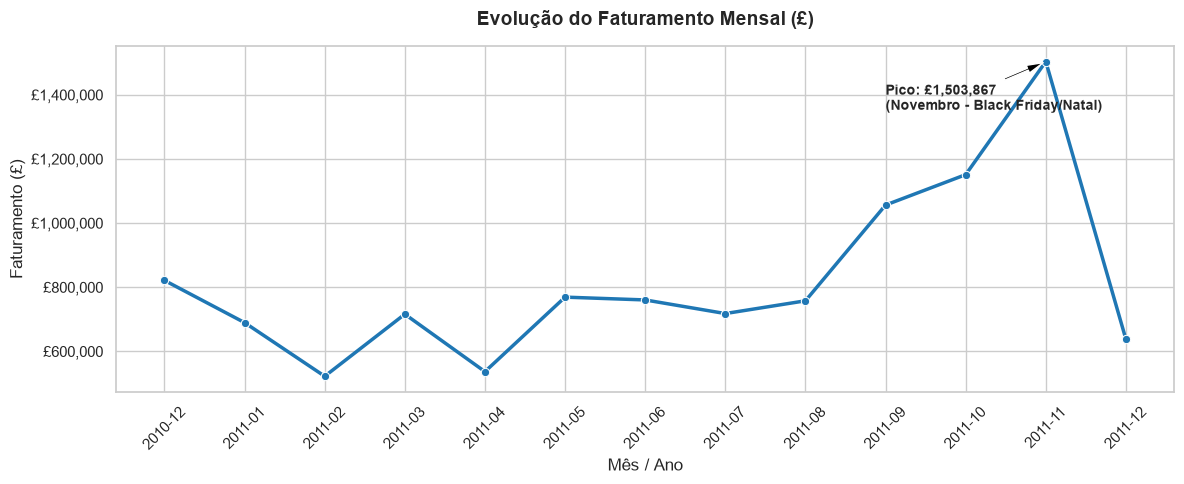

In [9]:
faturamento_mensal = (
    df_limpo.groupby(df_limpo['InvoiceDate'].dt.to_period('M'))['TotalVenda']
    .sum()
    .reset_index()
)
faturamento_mensal['InvoiceDate'] = faturamento_mensal['InvoiceDate'].astype(str)

plt.figure(figsize=(12, 5))
ax = sns.lineplot(data=faturamento_mensal, x='InvoiceDate', y='TotalVenda', marker='o', color='#1f77b4', linewidth=2.5)
plt.title('Evolução do Faturamento Mensal (£)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mês / Ano', fontsize=12)
plt.ylabel('Faturamento (£)', fontsize=12)
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter('£{x:,.0f}')

# Destaque do mês de pico
pico_idx = faturamento_mensal['TotalVenda'].idxmax()
pico_mes = faturamento_mensal.loc[pico_idx, 'InvoiceDate']
pico_val = faturamento_mensal.loc[pico_idx, 'TotalVenda']
plt.annotate(f'Pico: £{pico_val:,.0f}\n(Novembro - Black Friday/Natal)', 
             xy=(pico_idx, pico_val), 
             xytext=(pico_idx - 2, pico_val * 0.9),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
             fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


### 5.2 Top 10 Produtos Mais Vendidos em Quantidade

C:\Users\VITOR EMANUEL\AppData\Local\Temp\ipykernel_22580\1653946644.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_produtos, x='Quantity', y='Description', palette='Blues_r')


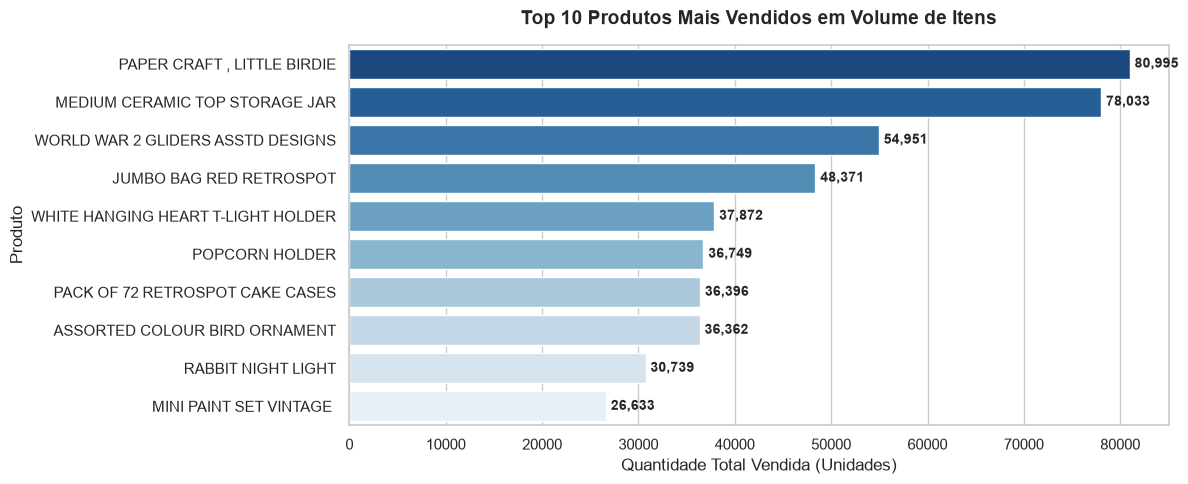

In [10]:
top_produtos = (
    df_limpo.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.barplot(data=top_produtos, x='Quantity', y='Description', palette='Blues_r')
plt.title('Top 10 Produtos Mais Vendidos em Volume de Itens', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Quantidade Total Vendida (Unidades)', fontsize=12)
plt.ylabel('Produto', fontsize=12)

for i, v in enumerate(top_produtos['Quantity']):
    plt.text(v + 500, i, f'{v:,}', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


### 5.3 Top 10 Países por Faturamento

C:\Users\VITOR EMANUEL\AppData\Local\Temp\ipykernel_22580\570583788.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=faturamento_paises, x='TotalVenda', y='Country', palette='viridis')


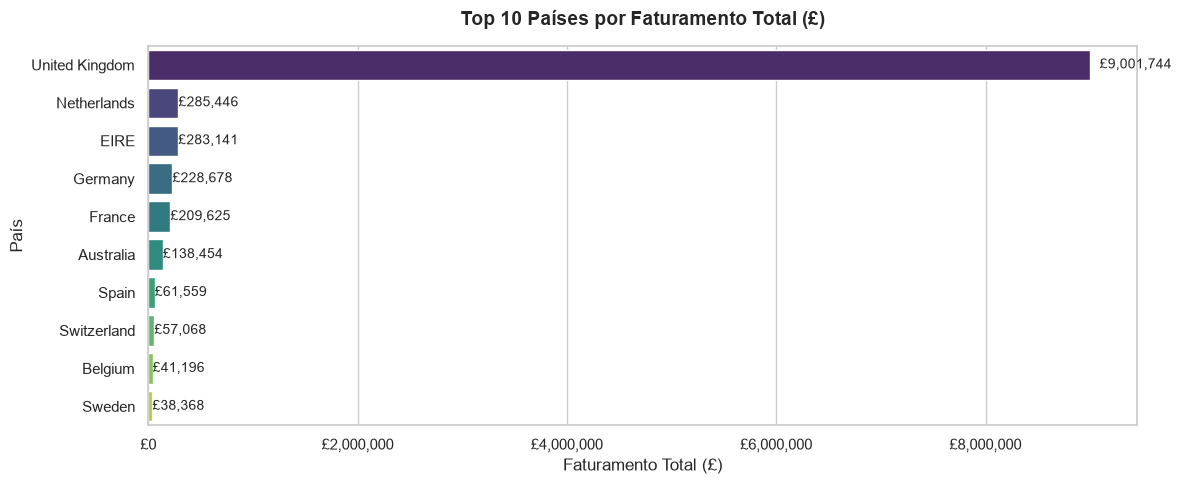

In [11]:
faturamento_paises = (
    df_limpo.groupby('Country')['TotalVenda']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.barplot(data=faturamento_paises, x='TotalVenda', y='Country', palette='viridis')
plt.title('Top 10 Países por Faturamento Total (£)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Faturamento Total (£)', fontsize=12)
plt.ylabel('País', fontsize=12)
plt.gca().xaxis.set_major_formatter('£{x:,.0f}')

for i, v in enumerate(faturamento_paises['TotalVenda']):
    plt.text(v * 1.01, i, f'£{v:,.0f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()


## 6. Conclusões e Principais Insights

1. **Qualidade e Governança dos Dados:**
   - A investigação minuciosa permitiu separar transações comerciais legítimas de **baixas de estoque, avarias e cancelamentos**, evitando distorções graves nas métricas financeiras.
   - Foram preservadas **392.732 linhas válidas**, responsáveis pelo faturamento real do negócio.

2. **Comportamento Temporal e Sazonalidade:**
   - O faturamento apresentou crescimento consistente ao longo do segundo semestre de 2011, atingindo o pico absoluto em **novembro de 2011 (£ 1.509.496,33)** devido às compras preparatórias de Black Friday e festividades natalinas.

3. **Concentração Geográfica:**
   - O **Reino Unido** representa a maior fatia do faturamento (mais de 80%), seguido por mercados europeus relevantes como **Holanda**, **Irlanda (EIRE)**, **Alemanha** e **França**.

4. **Mix de Produtos:**
   - Os itens mais vendidos em volume concentram-se em utilidades decorativas, presentes e artigos de papelaria com alta saída unitária e ticket de baixo a médio.
